# 1. Project Overview
## Predicting Prolonged Hospital Length of Stay Using ICU Patient Data
Can first-48-hour ICU information predict a hospital stay longer than 14 days among patients who survive hospitalization?

We use training set A from the [PhysioNet Challenge 2012, version 1.0.0](https://physionet.org/content/challenge-2012/1.0.0/). The source describes adult ICU stays of at least 48 hours, admission descriptors, time-stamped measurements, and separate hospital outcomes. Hospital length of stay is distinct from ICU length of stay. This notebook inspects data and defines outcomes; it does not train models.

In [2]:
from pathlib import Path
from urllib.request import urlopen
import shutil
import zipfile

import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 60)
# Locate the project from either the root or notebooks/ working directory.
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "pixi.toml").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from the project root or its notebooks folder.")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)

Project root: D:\Ruiyang Hu\duke\26Fall\Biostat707\BIOS707-Final-Project


# 2. Data Download
Download only `set-a.zip` and `Outcomes-a.txt` from the official versioned source. Existing downloads are reused. Extracted patient files stay under `data/raw/`, which is excluded from version control. No raw data are uploaded.

In [3]:
BASE_URL = "https://physionet.org/files/challenge-2012/1.0.0/"
for filename in ["set-a.zip", "Outcomes-a.txt"]:
    destination = RAW_DIR / filename
    if not destination.exists():
        temporary = destination.with_suffix(destination.suffix + ".part")
        try:
            with urlopen(BASE_URL + filename, timeout=120) as response, temporary.open("wb") as output:
                shutil.copyfileobj(response, output)
            temporary.replace(destination)
        finally:
            temporary.unlink(missing_ok=True)
    print(filename, destination.stat().st_size, "bytes")

with zipfile.ZipFile(RAW_DIR / "set-a.zip") as archive:
    # Validate all destinations before extraction.
    for member in archive.infolist():
        target = (RAW_DIR / member.filename).resolve()
        if not target.is_relative_to(RAW_DIR.resolve()):
            raise ValueError("Unsafe ZIP member path")
    archive.extractall(RAW_DIR)
patient_files = sorted((RAW_DIR / "set-a").glob("*.txt"))
if not patient_files:
    raise FileNotFoundError("No patient files found in data/raw/set-a/.")
print("Extracted patient files:", len(patient_files))

set-a.zip 7938449 bytes
Outcomes-a.txt 79219 bytes
Extracted patient files: 4000


# 3. Load Outcomes
Read the outcome table with pandas. Per the source documentation, `-1` means missing or unknown; convert it to missing rather than treating it as an observed value. `RecordID` identifies an ICU stay, not necessarily a unique person.

In [4]:
outcomes = pd.read_csv(RAW_DIR / "Outcomes-a.txt", na_values=[-1])
outcomes.columns = outcomes.columns.str.strip()
required = ["RecordID", "Length_of_stay", "In-hospital_death"]
if not set(required).issubset(outcomes.columns):
    raise ValueError("Required outcome columns are missing.")
outcomes["RecordID"] = outcomes["RecordID"].astype("Int64")
display(outcomes.head())
display(outcomes.dtypes.rename("dtype").to_frame())
print("Column names:", outcomes.columns.tolist())

,RecordID,SAPS-I,SOFA,Length_of_stay,Survival,In-hospital_death
0,132539,6.0,1.0,5.0,NaN,0
1,132540,16.0,8.0,8.0,NaN,0
2,132541,21.0,11.0,19.0,NaN,0
3,132543,7.0,1.0,9.0,575.0,0
4,132545,17.0,2.0,4.0,918.0,0


,dtype
RecordID,Int64
SAPS-I,float64
SOFA,float64
Length_of_stay,float64
Survival,float64
In-hospital_death,int64


Column names: ['RecordID', 'SAPS-I', 'SOFA', 'Length_of_stay', 'Survival', 'In-hospital_death']


# 4. Data Quality
Check outcome rows, unique ICU-stay IDs, duplicate rows and IDs, and missing outcomes. Compare outcome IDs with filenames and the RecordID stored inside each patient file. Stop on ambiguous identifiers before building study populations.

In [5]:
file_ids = pd.Index([int(path.stem) for path in patient_files], name="RecordID")
outcome_ids = pd.Index(outcomes["RecordID"].dropna().astype(int).unique())
quality = pd.Series({
    "Outcome rows": len(outcomes),
    "Unique outcome RecordIDs": outcomes["RecordID"].nunique(),
    "Patient files": len(patient_files),
    "Duplicate outcome rows": outcomes.duplicated().sum(),
    "Duplicate outcome RecordIDs": outcomes["RecordID"].duplicated().sum(),
    "Missing outcome RecordIDs": outcomes["RecordID"].isna().sum(),
    "Duplicate filename RecordIDs": file_ids.duplicated().sum(),
})
display(quality.rename("count").to_frame())
display(outcomes.isna().sum().rename("missing_values").to_frame())
missing_files = outcome_ids.difference(file_ids)
missing_outcomes = file_ids.difference(outcome_ids)
print("Outcome IDs without patient files:", missing_files.tolist())
print("Patient IDs without outcomes:", missing_outcomes.tolist())

# Keep only availability flags rather than all patient measurement tables.
predictor_names = sorted(set("""Age Gender Height ICUType Weight Albumin ALP ALT AST
Bilirubin BUN Cholesterol Creatinine DiasABP FiO2 GCS Glucose HCO3 HCT HR K Lactate
Mg MAP MechVent Na NIDiasABP NIMAP NISysABP PaCO2 PaO2 pH Platelets RespRate SaO2
SysABP Temp TropI TropT Urine WBC""".split()))
availability_rows = {}
invalid_time_rows = 0
outside_window_rows = 0
id_mismatches = []
for path in patient_files:
    frame = pd.read_csv(path, na_values=[-1])
    stored_ids = pd.to_numeric(frame.loc[frame["Parameter"].eq("RecordID"), "Value"], errors="coerce")
    if len(stored_ids) != 1 or stored_ids.iloc[0] != int(path.stem):
        id_mismatches.append(path.name)
    time_parts = frame["Time"].str.extract(r"^(\d+):([0-5]\d)$")
    minutes = pd.to_numeric(time_parts[0], errors="coerce") * 60 + pd.to_numeric(time_parts[1], errors="coerce")
    invalid_time_rows += int(minutes.isna().sum())
    outside_window_rows += int((minutes.notna() & ~minutes.between(0, 48 * 60)).sum())
    values = pd.to_numeric(frame["Value"], errors="coerce")
    observed = frame.loc[minutes.between(0, 48 * 60) & values.notna() & values.ge(0), "Parameter"]
    availability_rows[int(path.stem)] = observed.value_counts().reindex(predictor_names, fill_value=0).gt(0)
print("Files with internal RecordID mismatches:", id_mismatches)
assert outcomes["RecordID"].notna().all(), "Resolve missing RecordIDs first."
assert not outcomes["RecordID"].duplicated().any(), "Resolve duplicate RecordIDs first."
assert not file_ids.duplicated().any() and not id_mismatches, "Resolve patient file IDs first."

valid_los = outcomes["Length_of_stay"].notna() & outcomes["Length_of_stay"].ge(0)
valid_death = outcomes["In-hospital_death"].isin([0, 1])
matched = outcomes["RecordID"].isin(file_ids)
display(pd.Series({
    "Missing or invalid length of stay": (~valid_los).sum(),
    "Missing or invalid death status": (~valid_death).sum(),
    "Matched with valid outcomes": (matched & valid_los & valid_death).sum(),
}).rename("count").to_frame())

,count
Outcome rows,4000
Unique outcome RecordIDs,4000
Patient files,4000
Duplicate outcome rows,0
Duplicate outcome RecordIDs,0
Missing outcome RecordIDs,0
Duplicate filename RecordIDs,0


,missing_values
RecordID,0
SAPS-I,190
SOFA,144
Length_of_stay,60
Survival,2526
In-hospital_death,0


Outcome IDs without patient files: []
Patient IDs without outcomes: []
Files with internal RecordID mismatches: []


,count
Missing or invalid length of stay,60
Missing or invalid death status,0
Matched with valid outcomes,3940


# 5. Outcome Distribution
Summarize hospital length of stay in days and in-hospital death status. The percentage above 14 days uses all outcome records with a valid length of stay as its denominator, including deaths.

In [6]:
display(outcomes.loc[valid_los, "Length_of_stay"].describe().to_frame())
display(outcomes["In-hospital_death"].value_counts(dropna=False).rename("count").to_frame())
long_stays = outcomes.loc[valid_los, "Length_of_stay"].gt(14)
display(pd.DataFrame({"valid_LOS_records": [len(long_stays)],
                      "stays_over_14_days": [int(long_stays.sum())],
                      "percent_over_14_days": [100 * long_stays.mean()]}))

,Length_of_stay
count,3940.000000
mean,13.661675
std,12.207897
min,1.000000
25%,6.000000
50%,10.000000
75%,17.000000
max,154.000000


,count
In-hospital_death,
0,3446
1,554


,valid_LOS_records,stays_over_14_days,percent_over_14_days
0,3940,1204,30.558376


# 6. Primary Study Population
Eligibility requires a matched patient record, a nonmissing nonnegative hospital length of stay, and death status coded 0 or 1. Restrict the primary analysis to hospital survivors and define `prolonged_stay = 1` for stays strictly longer than 14 days. A stay of exactly 14 days is coded 0. Conditioning on eventual survival limits interpretation to survivors.

In [7]:
eligible = outcomes.loc[matched & valid_los & valid_death].copy()
primary = eligible.loc[eligible["In-hospital_death"].eq(0)].copy()
primary["prolonged_stay"] = primary["Length_of_stay"].gt(14).astype(int)

def outcome_table(series):
    counts = series.value_counts().reindex([0, 1], fill_value=0)
    return pd.DataFrame({"count": counts, "percent": counts / len(series) * 100})

print("Eligible ICU stays:", len(eligible))
print("Primary survivor ICU stays:", len(primary))
display(outcome_table(primary["prolonged_stay"]))

Eligible ICU stays: 3940
Primary survivor ICU stays: 3386


,count,percent
prolonged_stay,,
0,2361,69.728293
1,1025,30.271707


# 7. Sensitivity Analysis Definition
Use all eligible stays, including deaths. Define `composite_outcome = 1` for in-hospital death **or** hospital length of stay longer than 14 days. This represents a different clinical endpoint and population from the survivor-only primary analysis. Records with unknown death status or length of stay are excluded consistently from both definitions.

In [8]:
eligible["composite_outcome"] = (
    eligible["In-hospital_death"].eq(1) | eligible["Length_of_stay"].gt(14)
).astype(int)
display(outcome_table(eligible["composite_outcome"]))

,count,percent
composite_outcome,,
0,2361,59.923858
1,1579,40.076142


# 8. Exploratory Plots
Plot observed hospital length of stay and the primary survivor outcome without trimming the long-stay tail. For predictor missingness, a variable is available when a patient has at least one nonmissing, nonnegative measurement between 00:00 and 48:00 inclusive. This is patient-level availability, not the fraction of measurement rows missing.

Use only admission descriptors and first-48-hour measurements. Exclude RecordID and every column from the outcome file from future predictors. The missingness table covers both the primary survivors and all eligible stays; no imputation or predictor aggregation for modeling is performed here.

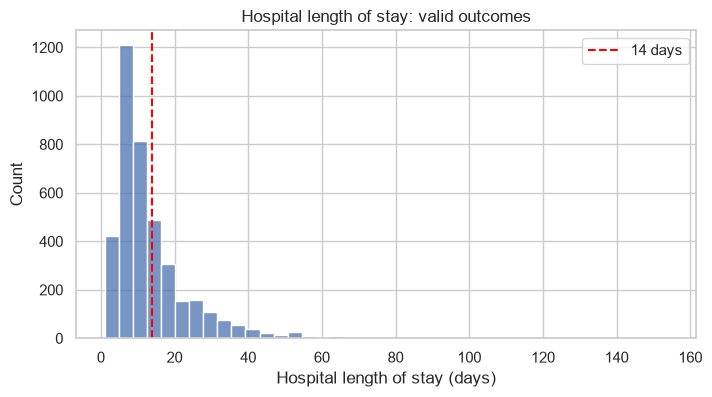

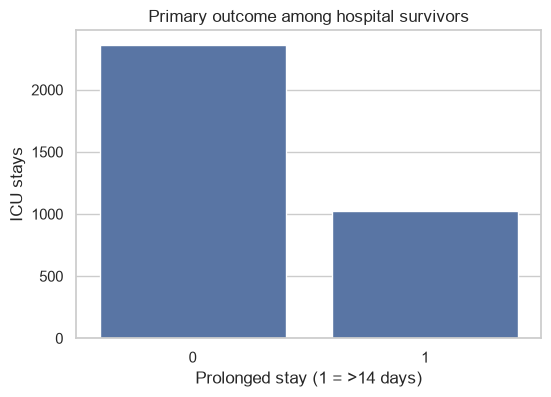

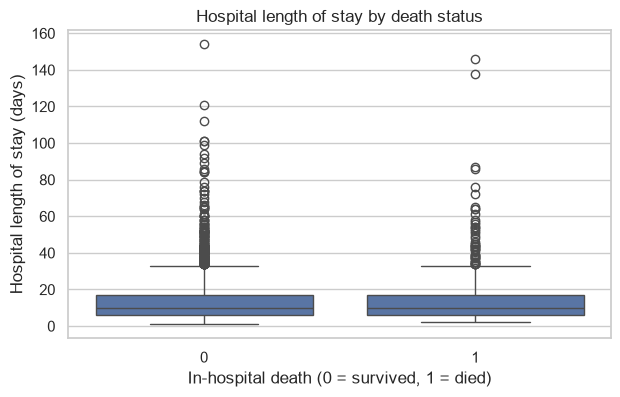

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=outcomes.loc[valid_los], x="Length_of_stay", bins=40, ax=ax)
ax.axvline(14, color="red", linestyle="--", label="14 days")
ax.set(title="Hospital length of stay: valid outcomes", xlabel="Hospital length of stay (days)")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=primary, x="prolonged_stay", order=[0, 1], ax=ax)
ax.set(title="Primary outcome among hospital survivors", xlabel="Prolonged stay (1 = >14 days)", ylabel="ICU stays")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=eligible, x="In-hospital_death", y="Length_of_stay", ax=ax)
ax.set(title="Hospital length of stay by death status", xlabel="In-hospital death (0 = survived, 1 = died)", ylabel="Hospital length of stay (days)")
plt.show()

Malformed time rows excluded: 0
Rows outside 0-48 hours excluded: 0


,primary_missing_n,primary_missing_percent,all_eligible_missing_percent
TropT,3386,100.00,100.00
TropI,3386,100.00,100.00
Cholesterol,3127,92.35,92.26
RespRate,2396,70.76,72.66
Albumin,2078,61.37,59.11
ALP,2021,59.69,57.18
Bilirubin,1998,59.01,56.47
ALT,1997,58.98,56.42
AST,1994,58.89,56.32
SaO2,1869,55.20,54.77


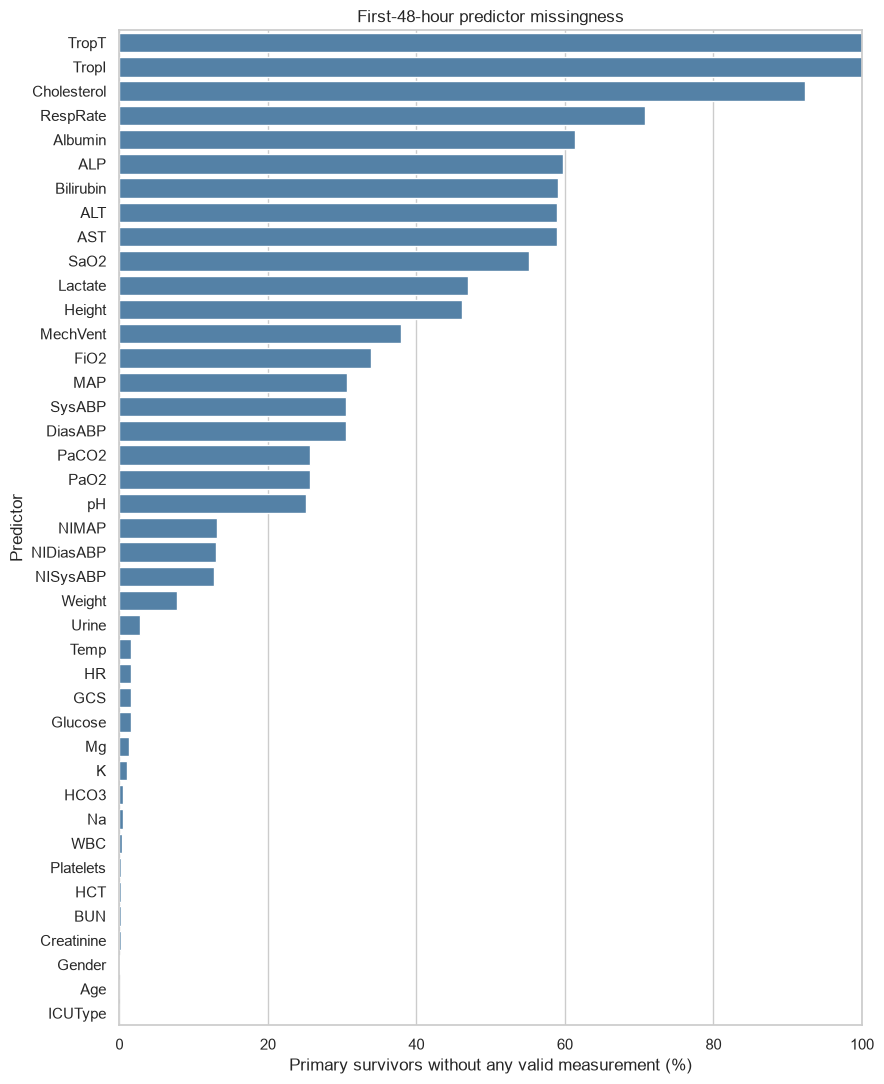

In [10]:
# Availability flags were collected while checking patient records in Section 4.
availability = pd.DataFrame.from_dict(availability_rows, orient="index").reindex(columns=predictor_names)
availability.index.name = "RecordID"
print("Malformed time rows excluded:", invalid_time_rows)
print("Rows outside 0-48 hours excluded:", outside_window_rows)
primary_available = availability.reindex(primary["RecordID"].astype(int))
all_available = availability.reindex(eligible["RecordID"].astype(int))
missingness = pd.DataFrame({
    "primary_missing_n": (~primary_available).sum(),
    "primary_missing_percent": (~primary_available).mean() * 100,
    "all_eligible_missing_percent": (~all_available).mean() * 100,
}).sort_values("primary_missing_percent", ascending=False)
display(missingness.round(2))
fig, ax = plt.subplots(figsize=(9, 11))
sns.barplot(data=missingness.reset_index(names="predictor"), x="primary_missing_percent", y="predictor", color="steelblue", ax=ax)
ax.set(xlim=(0, 100), xlabel="Primary survivors without any valid measurement (%)", ylabel="Predictor", title="First-48-hour predictor missingness")
plt.tight_layout()
plt.show()

# 9. Summary
The inspection checks outcome completeness and identifier alignment, defines the survivor-only primary population and all-eligible composite endpoint, and describes outcome balance and first-48-hour predictor availability. The cell below reports only values calculated during execution.

Later modeling must address implausible measurements, repeated or irregular observations, feature summaries, missing-data handling, class balance, and validation. Fit preprocessing and imputation using training data only. Use a 48-hour prediction time point and exclude outcomes, identifiers, and later information from predictors. Review hospital versus ICU admission timing, survivor selection, and whether repeated stays from the same person can be identified before choosing a split. These descriptive checks do not establish predictive performance or causality.

In [11]:
display(Markdown(
    f"Inspected **{len(outcomes):,} outcome records** and **{len(patient_files):,} patient files**. "
    f"There are **{len(missing_files)} outcome IDs without files** and **{len(missing_outcomes)} file IDs without outcomes**. "
    f"After eligibility checks, **{len(eligible):,} stays** remain; **{len(primary):,} survivors** form the primary population. "
    f"Among survivors, **{primary['prolonged_stay'].sum():,} ({primary['prolonged_stay'].mean():.1%})** have stays >14 days. "
    f"The composite endpoint occurs in **{eligible['composite_outcome'].sum():,} ({eligible['composite_outcome'].mean():.1%})** eligible stays. "
    "Predictor missingness is shown above and requires a prespecified strategy before modeling. No models were trained."
))

Inspected **4,000 outcome records** and **4,000 patient files**. There are **0 outcome IDs without files** and **0 file IDs without outcomes**. After eligibility checks, **3,940 stays** remain; **3,386 survivors** form the primary population. Among survivors, **1,025 (30.3%)** have stays >14 days. The composite endpoint occurs in **1,579 (40.1%)** eligible stays. Predictor missingness is shown above and requires a prespecified strategy before modeling. No models were trained.